In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=5)
SEED = 42
rng = np.random.default_rng(SEED)

## Task 1

Rasmussen & Williams Gaussian Processes for Machine Learning eq. 2.8

## Task 2

Plot the posterior predictive $p(y_{\ast} \mid x_{\ast}, X, y)$ for several values of the prior variance $\Sigma_0$. What happens in the limit $\Sigma_0 \to \infty$?

In [8]:
n = 10 # number of data points
X: np.ndarray = rng.uniform(-1, 1, size=(n, 1))
X = np.pad(X, ((0, 0), (1, 0)), mode="constant", constant_values=1)  # pad with ones for the bias term

# pick a constant w (of the model)
w = np.array([1, 2])

# standard deviation of the noise
noise_std = 0.4
noise_var = noise_std**2

# generate y with some noise
y = X @ w + rng.normal(0, noise_std, size=n)

# generate a set of points to plot the model's predictions - a uniform set of points with a padding term added to each point
X_star = np.pad(np.linspace(-2, 2, 200).reshape(-1, 1), ((0, 0), (1, 0)), mode="constant", constant_values=1)

# define some prior sigmas
prior_sigmas = [np.eye(2, 2), np.array([[1, 0], [0, 0.1]]), np.array([[0.1, 0], [0, 1]]), np.array([[1, 0.5], [0.5, 1]])]

# prior Sigma_0 = tau^2 * I, from a tight prior around 0 to an almost flat one
prior_scales = [1e-3, 1e-2, 1e-1, 1, 10, 1e3]


### Posterior predictive

With prior $w \sim \mathcal{N}(0, \Sigma_0)$ and noise variance $\sigma_n^2$, the posterior is $w \mid X, y \sim \mathcal{N}(\mu, A^{-1})$ with $A = \frac{1}{\sigma_n^2} X^\top X + \Sigma_0^{-1}$ and $\mu = \frac{1}{\sigma_n^2} A^{-1} X^\top y$.

For a test input $x_\ast$, padded with a $1$ for the bias like the rows of $X$, the predictive distribution averages the likelihood of the new observation over all weights, each weighted by its posterior probability:

$$p(y_\ast \mid x_\ast, X, y) = \int p(y_\ast \mid x_\ast, w)\, p(w \mid X, y)\, dw = \int \mathcal{N}\!\left(y_\ast;\, x_\ast^\top w,\, \sigma_n^2\right) \mathcal{N}\!\left(w;\, \mu,\, A^{-1}\right) dw = \mathcal{N}\!\left(x_\ast^\top \mu,\; x_\ast^\top A^{-1} x_\ast + \sigma_n^2\right)$$

For $\Sigma_0 = \tau^2 I$ the mean is the ridge solution with $\lambda = \sigma_n^2 / \tau^2$.

In [9]:
def posterior_predictive(X, y, noise_var, prior_sigma, X_star):
    """Mean and variance of p(y* | x*, X, y) at every (padded) row x* of X_star."""

    A = X.T @ X / noise_var + np.linalg.inv(prior_sigma)

    mu_post = np.linalg.solve(A, X.T @ y / noise_var)

    # predictive mean x*^T mu for every test point at once, shape (n_test,)
    mean = X_star @ mu_post

    var = np.sum((X_star @ np.linalg.inv(A)) * X_star, axis=1) + noise_var

    return mean, var


def plot_predictive(ax, prior_sigma, title):
    """Predictive mean, +-2 sd bands for y* and f*, true line and data for one prior, drawn on the given axes."""
    mean, var = posterior_predictive(X, y, noise_var, prior_sigma, X_star)

    x_test = X_star[:, 1]

    sd_y = np.sqrt(var)  # y*: uncertainty about the weights plus the noise of a new observation
    sd_f = np.sqrt(var - noise_var)  # f*: only the uncertainty about the weights

    ax.fill_between(x_test, mean - 2 * sd_y, mean + 2 * sd_y, color="C0", alpha=0.2, label="y* ±2σ")
    ax.fill_between(x_test, mean - 2 * sd_f, mean + 2 * sd_f, color="C0", alpha=0.5, label="f* ±2σ (noiseless)")
    ax.plot(x_test, mean, color="C0", label="predictive mean")
    ax.plot(x_test, X_star @ w, "g--", lw=0.8, label="true model")  # noiseless line w1 + w2 * x
    ax.scatter(X[:, 1], y, color="k", s=12, label="data")
    ax.set_title(title)
    ax.set_xlabel("x*")
    ax.set_ylabel("y*")
    ax.label_outer()  # axis labels only on the outer panels of the grid

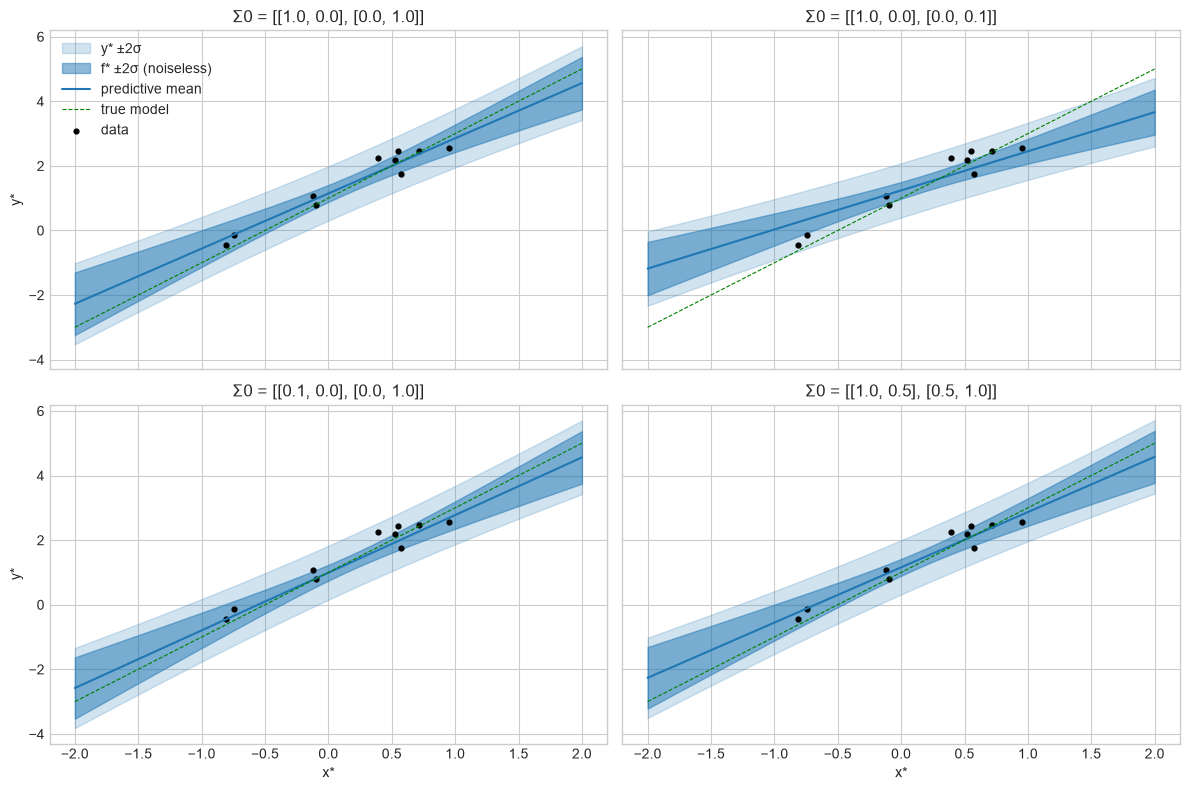

In [10]:
# the priors defined in `prior_sigmas`, one panel each
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, sigma in zip(axes.ravel(), prior_sigmas):
    title = f"Σ0 = {sigma.tolist()}"
    plot_predictive(ax, sigma, title)
axes[0, 0].legend(loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

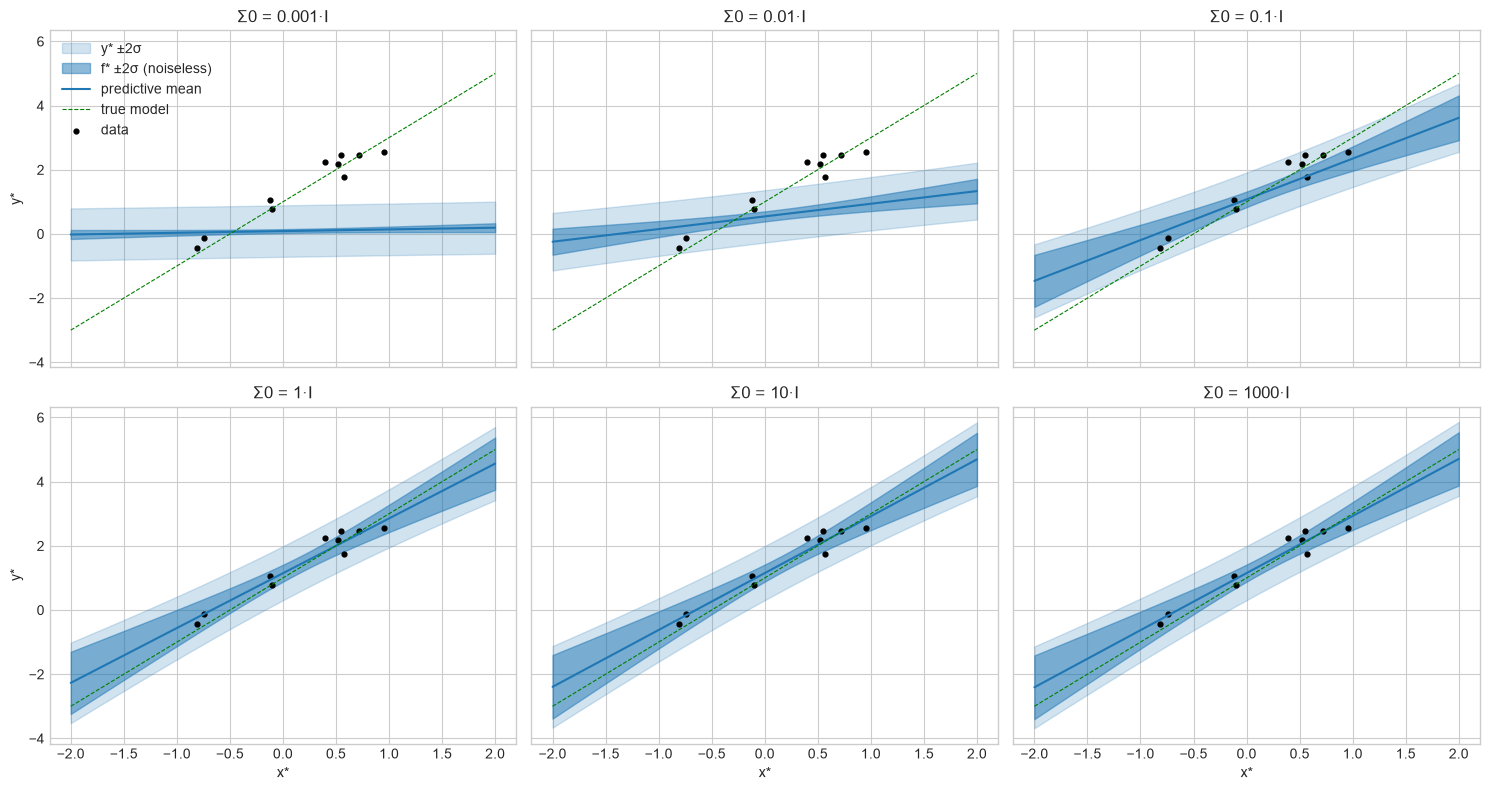

In [11]:
# Sigma_0 = tau^2 * I for each value in prior_scales, one panel each
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, tau2 in zip(axes.ravel(), prior_scales):
    plot_predictive(ax, tau2 * np.eye(2), f"Σ0 = {tau2:g}·I")
axes[0, 0].legend(loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

In [12]:
# limit Sigma_0 -> infinity: the predictive should approach the plain OLS prediction
XtX_inv = np.linalg.inv(X.T @ X)
w_ols = XtX_inv @ X.T @ y  # OLS weights (X^T X)^-1 X^T y
ols_mean = X_star @ w_ols  # OLS prediction at the test points
# classical OLS predictive variance: sigma_n^2 (1 + x*^T (X^T X)^-1 x*), again one value per test point
ols_var = noise_var * (1 + np.einsum("ij,jk,ik->i", X_star, XtX_inv, X_star))

# make the prior wider and wider and measure the largest gap to OLS over all test points
for tau2 in [1e-3, 1, 1e3, 1e6, 1e9]:
    mean, var = posterior_predictive(X, y, noise_var, tau2 * np.eye(2), X_star)
    print(f"tau^2={tau2:>7g}  max|mean - OLS mean| = {np.abs(mean - ols_mean).max():.1e}  max|var - OLS var| = {np.abs(var - ols_var).max():.1e}")

tau^2=  0.001  max|mean - OLS mean| = 4.5e+00  max|var - OLS var| = 2.4e-01
tau^2=      1  max|mean - OLS mean| = 1.5e-01  max|var - OLS var| = 1.2e-02
tau^2=   1000  max|mean - OLS mean| = 1.5e-04  max|var - OLS var| = 1.2e-05
tau^2=  1e+06  max|mean - OLS mean| = 1.5e-07  max|var - OLS var| = 1.2e-08
tau^2=  1e+09  max|mean - OLS mean| = 1.5e-10  max|var - OLS var| = 1.2e-11


**What happens as $\Sigma_0 \to \infty$?** The prior precision $\Sigma_0^{-1}$ goes to $0$, so $A \to X^\top X / \sigma_n^2$. Then

- $\mu \to (X^\top X)^{-1} X^\top y$, the OLS solution,
- the weight covariance $A^{-1} \to \sigma_n^2 (X^\top X)^{-1}$, the OLS sampling covariance,
- the predictive becomes $\mathcal{N}\!\left(x_\ast^\top \hat\beta_{\mathrm{OLS}},\; \sigma_n^2 \left(1 + x_\ast^\top (X^\top X)^{-1} x_\ast\right)\right)$, the classical OLS prediction interval.

So an infinitely wide (flat) prior means no regularisation: the posterior mean equals OLS, i.e. ridge with $\lambda = \sigma_n^2/\tau^2 \to 0$. The printed differences above shrink like $1/\tau^2$.

In the other direction ($\Sigma_0 \to 0$) the mean is pulled to the prior mean $0$ and the weight uncertainty vanishes, so only the noise $\sigma_n^2$ is left in the predictive variance. Here the prior only matters for $\tau^2 \lesssim 0.1$. With $n = 10$ points the data dominates for wider priors.

**Two bands in the plots.** The wide band is for $y_\ast$ (variance $x_\ast^\top A^{-1} x_\ast + \sigma_n^2$), where a new noisy observation will land. The dark inner band is for $f_\ast = x_\ast^\top w$ (variance $x_\ast^\top A^{-1} x_\ast$), where the true line probably is. Their variances differ by the constant noise $\sigma_n^2$. Only the inner band widens away from the data, with the $x_\ast^2$ term fanning out outside the training range.

## Task 3  
The posterior mean is a linear function of $y$:
   $\mu_{\ast} = A(X) y$ where $A$ depends on the data locations but not on $y$.
   If you wanted to learn this map from examples, what class of models would
   be sufficient? Does a linear model suffice, or do you need something
   nonlinear? What is the role of $X$ in the learned map?

**Answer.** Multiplying the posterior mean through by $\sigma_n^2$ gives

$$\mu = M(X)\, y, \qquad M(X) = \left(X^\top X + \sigma_n^2 \Sigma_0^{-1}\right)^{-1} X^\top \in \mathbb{R}^{2 \times n}$$

I call the map $M$ because $A$ is already the posterior precision in this notebook. The prediction is $x_\ast^\top \mu = \sum_j \alpha_j y_j$ with weights $\alpha_j(x_\ast, X)$ that depend on the inputs only, never on $y$.

**If $X$ is the same in every dataset, a linear model is enough.** Then $y \mapsto \mu$ is one fixed matrix.
- Linear regression without a bias (the prior mean is $0$, so $\mu(0) = 0$) on pairs $(y_k, \mu_k)$ recovers $M$ exactly once there are $n$ linearly independent $y_k$.
- Even if the targets are the true weights $w_k$ instead of $\mu_k$, linear regression finds the same $M$. For a Gaussian prior and noise, the best squared-error estimate of $w$ is the posterior mean, which is linear in $y$.

**If $X$ changes between datasets, a linear model is not enough.** The map is linear in $y$ but nonlinear in $X$, because of the inverse.
- Example with one data point and one weight: $\mu = \dfrac{x\,y}{x^2 + \sigma_n^2/\tau^2}$. This is not even bilinear in $(x, y)$, so no model that is linear in the inputs $(X, y)$ can represent it.
- A sufficient class is a neural network on $(X, y)$ (universal approximation). A better-structured one is $\mu = M_\theta(X)\, y$: a nonlinear network turns $X$ into the weights, and $y$ only enters linearly.
- The number of points $n$ can vary, and permuting the rows of $(X, y)$ together does not change $\mu$. A set model such as a transformer therefore fits well. The form $\sum_j \alpha_j(x_\ast, X)\, y_j$ is exactly an attention layer (Module 5).

**Role of $X$.** $X$ is not a feature that enters linearly. It is the context that selects which linear map is applied to $y$, i.e. it parametrises $M(X)$.
- For fixed $X$ it is just a constant absorbed into the learned matrix.
- For varying $X$ the nonlinear part of the network has to compute $M(X)$, effectively a matrix inverse. Ill-conditioned $X$ (Module 1) is again the hard case.
- If $\sigma_n$ or $\Sigma_0$ also vary between datasets, they have to be inputs as well.